# 16 — American Put Inverse PINN

## 1. Imports and configuration


In [46]:
import os
import math
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as Fnn

# Reproducibility
SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float64

# Contract and true parameters
K = 100.0
T = 1.0
r_true = 0.05
sigma_true = 0.20
q = 0.0

# Initial guesses for the inverse problem
r_initial = 0.10
sigma_initial = 0.40

# Domain
S_min = 0.0
S_max = 200.0

# Synthetic inverse data
AMERICAN_DATA_CSV = "15_american_synthetic_data.csv"

# This threshold is used only to report continuation-region coverage.
# It is not used to decide which points contribute to the training PDE loss.
continuation_data_eps_u = 1e-4

# Deep-OTM prices can be numerically tiny and weakly informative.
# This is used only for diagnostics and optional data weighting.
min_informative_price_u = 1e-4

# Keep this at 1.0 for the baseline.
continuation_data_weight = 1.0

# PINN sampling
N_f = 2000
N_terminal = 500
N_boundary_each = 500

# Network
hidden_width = 64
hidden_layers = 4

# Adam training
epochs = 80000
lr_nn = 1e-3
lr_r = 1e-3
lr_sigma = 1e-3
print_every = 500

# Training-loss weights
# The normalized data loss is much smaller numerically than the physics losses,
# so it is up-weighted in the inverse problem.
lambda_data = 1e3
lambda_vi = 1.0
lambda_tv = 1.0
lambda_terminal = 1.0
lambda_boundary_left = 1.0
lambda_boundary_right = 1.0

# These losses are still computed and reported as diagnostics,
# but they are not part of the optimization objective.
lambda_bs = 0.0
lambda_eq = 0.0
lambda_pde_cont = 0.0

# Optional optimization experiments
# Keep these settings for the clean baseline run.
# For experiment B, change lr_sigma to 1e-2.
# For experiment C, also set RUN_LBFGS = True.
RUN_LBFGS = False
lbfgs_max_iter = 2000

# For synthetic S_max=200 and K=100 this boundary is reasonable.
# For real data, do not automatically use max(observed S) as S_max.
USE_RIGHT_BOUNDARY = True

# Evaluation
n_t_eval = 100
n_S_eval = 100
continuation_eps_u = 1e-4
boundary_tol_u = 2e-3

OUTPUT_DIR = "16_american_inverse_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("device:", device)
print("true r =", r_true, "true sigma =", sigma_true)
print("initial r =", r_initial, "initial sigma =", sigma_initial)
print("lambda_data =", lambda_data, "lambda_vi =", lambda_vi)
print("RUN_LBFGS =", RUN_LBFGS)
print("dataset CSV:", AMERICAN_DATA_CSV)


device: cpu
true r = 0.05 true sigma = 0.2
initial r = 0.1 initial sigma = 0.4
lambda_data = 1000.0 lambda_vi = 1.0
RUN_LBFGS = False
dataset CSV: 15_american_synthetic_data.csv


## 2. Load the American synthetic observations


In [47]:
american_df = pd.read_csv(AMERICAN_DATA_CSV)

required_cols = {"t", "S", "V", "u"}
missing = required_cols - set(american_df.columns)
if missing:
    raise ValueError(f"Missing required columns in CSV: {missing}")

t_data_np = american_df["t"].to_numpy(dtype=np.float64)
S_data_np = american_df["S"].to_numpy(dtype=np.float64)
V_data_np = american_df["V"].to_numpy(dtype=np.float64)
u_data_np = american_df["u"].to_numpy(dtype=np.float64)

payoff_data_np = np.maximum(K - S_data_np, 0.0)
payoff_u_data_np = payoff_data_np / K
premium_u_np = u_data_np - payoff_u_data_np

continuation_like_np = premium_u_np > continuation_data_eps_u
exercise_like_np = (S_data_np < K) & (~continuation_like_np)
otm_np = S_data_np >= K

# Continuation observations with a non-negligible option value are the most
# useful part of the dataset for inverse parameter identification.
informative_continuation_np = (
    continuation_like_np
    & (u_data_np > min_informative_price_u)
)

continuation_fraction = continuation_like_np.mean()
exercise_like_fraction = exercise_like_np.mean()
otm_fraction = otm_np.mean()
informative_continuation_fraction = informative_continuation_np.mean()

coverage_df = pd.DataFrame([{
    "N_total": len(american_df),
    "continuation_fraction": continuation_fraction,
    "exercise_like_fraction": exercise_like_fraction,
    "OTM_fraction": otm_fraction,
    "informative_continuation_fraction": informative_continuation_fraction,
}])

print("Loaded:", AMERICAN_DATA_CSV)
print("shape:", american_df.shape)
display(coverage_df)
display(american_df.head())

if informative_continuation_fraction < 0.25:
    print(
        "WARNING: relatively few observations are in the informative continuation "
        "region. Parameter recovery, especially sigma, may be difficult. "
        "Consider continuation-focused sampling or a larger continuation_data_weight."
    )


Loaded: 15_american_synthetic_data.csv
shape: (2000, 5)


,N_total,continuation_fraction,exercise_like_fraction,OTM_fraction,informative_continuation_fraction
0,2000,0.303,0.43,0.504,0.303


,t,S,V,u,tau
0,0.976700,156.022814,1.210890e-49,1.210890e-51,0.023300
1,0.380196,146.920663,2.463828e-02,2.463828e-04,0.619804
2,0.923246,81.682005,1.831800e+01,1.831800e-01,0.076754
3,0.261692,28.791475,7.120852e+01,7.120852e-01,0.738308
4,0.319097,160.913043,5.818620e-03,5.818620e-05,0.680903


### Why report continuation-region coverage?

For an American put, observations in the exercise region satisfy approximately

\[
V=K-S,
\]

which is essentially independent of \(r\) and \(\sigma\). Those observations therefore contribute little direct information for identifying the inverse parameters.

Deep out-of-the-money observations can also have very small prices and weak sensitivity. The notebook reports these fractions before training and allows continuation-region observations to be up-weighted if later diagnostics show poor identification.


## 3. Inverse PINN model — jointly learn the price surface, r, and sigma


In [48]:
def inverse_softplus(x):
    # Return z such that softplus(z) = x for x > 0.
    x = float(x)
    if x <= 0.0:
        raise ValueError("inverse_softplus requires x > 0.")
    return math.log(math.expm1(x))


class AmericanInversePINN(nn.Module):
    """
    Input: raw (t,S)
    Internal normalization: t,S -> [-1,1]
    Output: u = V/K

    r and sigma are trainable positive parameters.
    """

    def __init__(self, r_initial, sigma_initial):
        super().__init__()

        layers = []
        in_dim = 2

        for _ in range(hidden_layers):
            layers.append(nn.Linear(in_dim, hidden_width))
            layers.append(nn.Tanh())
            in_dim = hidden_width

        layers.append(nn.Linear(in_dim, 1))
        self.net = nn.Sequential(*layers)

        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

        self.raw_r = nn.Parameter(
            torch.tensor(
                inverse_softplus(r_initial),
                device=device,
                dtype=dtype
            )
        )

        self.raw_sigma = nn.Parameter(
            torch.tensor(
                inverse_softplus(sigma_initial),
                device=device,
                dtype=dtype
            )
        )

    def normalize_inputs(self, t, S):
        t_n = 2.0 * t / T - 1.0
        S_n = 2.0 * (S - S_min) / (S_max - S_min) - 1.0
        return torch.cat([t_n, S_n], dim=1)

    def r(self):
        # Guarantees r > 0.
        return Fnn.softplus(self.raw_r) + 1e-10

    def sigma(self):
        # Volatility must also stay positive.
        return Fnn.softplus(self.raw_sigma) + 1e-10

    def forward(self, t, S):
        x = self.normalize_inputs(t, S)

        # Smooth nonnegative output; smoothness matters because V_SS is needed.
        u = Fnn.softplus(self.net(x))
        return u


model = AmericanInversePINN(
    r_initial=r_initial,
    sigma_initial=sigma_initial
).to(device=device, dtype=dtype)

print("initial learned r     =", model.r().item())
print("initial learned sigma =", model.sigma().item())


initial learned r     = 0.10000000010000001
initial learned sigma = 0.40000000010000003


## 4. American Black–Scholes operator


In [49]:
def american_bs_operator(model, t, S, r, sigma, q=0.0, create_graph=True):
    """
    For u = V/K:

    F[u] = u_t
           + 0.5 sigma^2 S^2 u_SS
           + (r-q) S u_S
           - r u
    """

    if not t.requires_grad:
        t = t.clone().detach().requires_grad_(True)

    if not S.requires_grad:
        S = S.clone().detach().requires_grad_(True)

    u = model(t, S)

    u_t = torch.autograd.grad(
        u, t,
        grad_outputs=torch.ones_like(u),
        create_graph=create_graph,
        retain_graph=True
    )[0]

    u_S = torch.autograd.grad(
        u, S,
        grad_outputs=torch.ones_like(u),
        create_graph=True,
        retain_graph=True
    )[0]

    u_SS = torch.autograd.grad(
        u_S, S,
        grad_outputs=torch.ones_like(u_S),
        create_graph=create_graph,
        retain_graph=True
    )[0]

    F = (
        u_t
        + 0.5 * sigma**2 * S**2 * u_SS
        + (r - q) * S * u_S
        - r * u
    )

    return F, u, u_t, u_S, u_SS


## 5. Convert observed data to tensors and sample physics/condition points


In [50]:
# Data tensors: loaded ONLY from CSV
t_data = torch.tensor(
    t_data_np[:, None], device=device, dtype=dtype
)

S_data = torch.tensor(
    S_data_np[:, None], device=device, dtype=dtype
)

u_data = torch.tensor(
    u_data_np[:, None], device=device, dtype=dtype
)

informative_continuation = torch.tensor(
    informative_continuation_np[:, None],
    device=device,
    dtype=torch.bool
)

data_weights = torch.ones_like(u_data)

if continuation_data_weight != 1.0:
    data_weights = torch.where(
        informative_continuation,
        torch.full_like(u_data, continuation_data_weight),
        data_weights
    )


def rand_uniform(n, low, high):
    return low + (high - low) * torch.rand(
        (n, 1), device=device, dtype=dtype
    )


# Collocation points
t_f = rand_uniform(N_f, 0.0, T).requires_grad_(True)
S_f = rand_uniform(N_f, S_min, S_max).requires_grad_(True)

# Terminal points
t_T = torch.full(
    (N_terminal, 1), T,
    device=device, dtype=dtype
)

S_T = rand_uniform(N_terminal, S_min, S_max)

u_T_target = torch.relu(
    torch.tensor(K, device=device, dtype=dtype) - S_T
) / K

# Left boundary S=0
# For an American put, immediate exercise gives V=K => u=1.
t_b0 = rand_uniform(N_boundary_each, 0.0, T)
S_b0 = torch.zeros(
    (N_boundary_each, 1),
    device=device, dtype=dtype
)
u_b0_target = torch.ones_like(t_b0)

# Right boundary S=S_max
# For sufficiently large S, American put value is approximately 0.
t_bmax = rand_uniform(N_boundary_each, 0.0, T)
S_bmax = torch.full(
    (N_boundary_each, 1), S_max,
    device=device, dtype=dtype
)
u_bmax_target = torch.zeros_like(t_bmax)


## 6. Inverse loss function


In [51]:
mse = nn.MSELoss()


def compute_losses(model):
    r = model.r()
    sigma = model.sigma()

    # 1. Data loss
    u_pred_data = model(t_data, S_data)

    squared_data_error = (u_pred_data - u_data) ** 2
    loss_data = torch.sum(
        data_weights * squared_data_error
    ) / torch.sum(data_weights)

    # Diagnostic data losses by region
    if torch.any(informative_continuation):
        loss_data_cont = torch.mean(
            squared_data_error[informative_continuation]
        )
    else:
        loss_data_cont = torch.tensor(
            float("nan"), device=device, dtype=dtype
        )

    noninformative_mask = ~informative_continuation
    if torch.any(noninformative_mask):
        loss_data_other = torch.mean(
            squared_data_error[noninformative_mask]
        )
    else:
        loss_data_other = torch.tensor(
            float("nan"), device=device, dtype=dtype
        )

    # 2. American Black-Scholes operator
    F, u_f, _, _, _ = american_bs_operator(
        model,
        t_f,
        S_f,
        r,
        sigma,
        q=q,
        create_graph=True
    )

    payoff_u = torch.relu(
        torch.tensor(K, device=device, dtype=dtype) - S_f
    ) / K

    gap_u = u_f - payoff_u

    # Variational inequality:
    # min(-F, u - payoff) = 0
    vi_res = torch.minimum(-F, gap_u)
    loss_vi = torch.mean(vi_res ** 2)

    # Extra obstacle stabilization:
    # u - payoff >= 0
    loss_tv = torch.mean(torch.relu(-gap_u) ** 2)

    # The next three quantities are diagnostics only.
    # They do not contribute to total loss in the baseline configuration.

    # F <= 0
    loss_bs = torch.mean(torch.relu(F) ** 2)

    # F * (u - payoff) = 0
    loss_eq = torch.mean((F * gap_u) ** 2)

    # Diagnostic continuation-region PDE residual.
    # The hard mask is never used to train r or sigma.
    continuation_mask = (
        gap_u.detach() > continuation_eps_u
    ).squeeze(-1)

    if torch.any(continuation_mask):
        loss_pde_cont = torch.mean(
            F[continuation_mask] ** 2
        )
        continuation_collocation_fraction = (
            continuation_mask.to(dtype).mean()
        )
    else:
        loss_pde_cont = torch.zeros(
            (), device=device, dtype=dtype
        )
        continuation_collocation_fraction = torch.zeros(
            (), device=device, dtype=dtype
        )

    # 3. Terminal condition
    u_T_pred = model(t_T, S_T)
    loss_terminal = mse(u_T_pred, u_T_target)

    # 4. Boundary conditions
    u_b0_pred = model(t_b0, S_b0)
    loss_boundary_left = mse(u_b0_pred, u_b0_target)

    if USE_RIGHT_BOUNDARY:
        u_bmax_pred = model(t_bmax, S_bmax)
        loss_boundary_right = mse(u_bmax_pred, u_bmax_target)
    else:
        loss_boundary_right = torch.zeros(
            (), device=device, dtype=dtype
        )

    total = (
        lambda_data * loss_data
        + lambda_vi * loss_vi
        + lambda_tv * loss_tv
        + lambda_terminal * loss_terminal
        + lambda_boundary_left * loss_boundary_left
        + lambda_boundary_right * loss_boundary_right
    )

    return {
        "total": total,
        "data": loss_data,
        "data_cont": loss_data_cont,
        "data_other": loss_data_other,
        "vi": loss_vi,
        "tv": loss_tv,
        "bs": loss_bs,
        "eq": loss_eq,
        "pde_cont": loss_pde_cont,
        "cont_colloc_fraction": continuation_collocation_fraction,
        "terminal": loss_terminal,
        "boundary_left": loss_boundary_left,
        "boundary_right": loss_boundary_right,
        "r": r,
        "sigma": sigma,
    }


The inverse problem uses both observed prices and American-option physics.

The main physics loss is

\[
L_{\mathrm{VI}}
=
\frac{1}{N_f}
\sum_{i=1}^{N_f}
\left[
\min\left(-F_i,\,u_i-\phi_i\right)
\right]^2.
\]


## 7. Train the inverse PINN


In [52]:
optimizer = torch.optim.Adam([
    {
        "params": model.net.parameters(),
        "lr": lr_nn,
    },
    {
        "params": [model.raw_r],
        "lr": lr_r,
    },
    {
        "params": [model.raw_sigma],
        "lr": lr_sigma,
    },
])

history = []
start = time.time()

for epoch in range(1, epochs + 1):
    optimizer.zero_grad()

    losses = compute_losses(model)
    losses["total"].backward()
    optimizer.step()

    if epoch == 1 or epoch % print_every == 0:
        row = {
            "epoch": epoch,
            **{
                k: float(v.detach().cpu())
                for k, v in losses.items()
            }
        }
        history.append(row)

        print(
            f"Epoch {epoch:6d} | "
            f"total={row['total']:.3e} | "
            f"data={row['data']:.3e} | "
            f"data_cont={row['data_cont']:.3e} | "
            f"vi={row['vi']:.3e} | "
            f"tv={row['tv']:.3e} | "
            f"bs_diag={row['bs']:.3e} | "
            f"eq_diag={row['eq']:.3e} | "
            f"pde_cont_diag={row['pde_cont']:.3e} | "
            f"T={row['terminal']:.3e} | "
            f"B0={row['boundary_left']:.3e} | "
            f"Bmax={row['boundary_right']:.3e} | "
            f"r={row['r']:.6f} | "
            f"sigma={row['sigma']:.6f}"
        )

adam_elapsed = time.time() - start
print(f"\nAdam training time: {adam_elapsed/60:.2f} minutes")

history_df = pd.DataFrame(history)
history_df.to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"),
    index=False
)

if RUN_LBFGS:
    print("\nStarting L-BFGS refinement")

    lbfgs = torch.optim.LBFGS(
        model.parameters(),
        lr=1.0,
        max_iter=lbfgs_max_iter,
        history_size=50,
        tolerance_grad=1e-12,
        tolerance_change=1e-14,
        line_search_fn="strong_wolfe",
    )

    def closure():
        lbfgs.zero_grad()
        loss = compute_losses(model)["total"]
        loss.backward()
        return loss

    lbfgs.step(closure)

    final_after_lbfgs = compute_losses(model)

    print("\nAfter L-BFGS")
    print({
        k: float(v.detach().cpu())
        for k, v in final_after_lbfgs.items()
    })

r_hat = model.r().detach().cpu().item()
sigma_hat = model.sigma().detach().cpu().item()

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "r_hat": r_hat,
        "sigma_hat": sigma_hat,
        "r_true": r_true,
        "sigma_true": sigma_true,
        "r_initial": r_initial,
        "sigma_initial": sigma_initial,
        "K": K,
        "T": T,
        "q": q,
        "S_min": S_min,
        "S_max": S_max,
        "hidden_width": hidden_width,
        "hidden_layers": hidden_layers,
        "continuation_data_fraction": continuation_fraction,
        "informative_continuation_fraction": informative_continuation_fraction,
        "continuation_data_weight": continuation_data_weight,
        "lambda_data": lambda_data,
        "lambda_vi": lambda_vi,
        "lambda_tv": lambda_tv,
        "lambda_bs": lambda_bs,
        "lambda_eq": lambda_eq,
        "lambda_pde_cont": lambda_pde_cont,
        "lr_nn": lr_nn,
        "lr_r": lr_r,
        "lr_sigma": lr_sigma,
        "run_lbfgs": RUN_LBFGS,
        "use_right_boundary": USE_RIGHT_BOUNDARY,
    },
    os.path.join(OUTPUT_DIR, "16_american_inverse_pinn.pt")
)

print("\nRecovered parameters")
print("r_hat     =", r_hat, "| r_true     =", r_true)
print("sigma_hat =", sigma_hat, "| sigma_true =", sigma_true)


Epoch      1 | total=2.594e+02 | data=2.587e-01 | data_cont=3.876e-01 | vi=6.204e-03 | tv=6.779e-04 | bs_diag=5.927e-03 | eq_diag=1.505e-03 | pde_cont_diag=5.718e-03 | T=3.383e-01 | B0=2.080e-02 | Bmax=3.039e-01 | r=0.100000 | sigma=0.400000
Epoch    500 | total=5.197e-02 | data=5.135e-05 | data_cont=7.885e-05 | vi=3.595e-04 | tv=6.423e-06 | bs_diag=3.402e-04 | eq_diag=4.725e-07 | pde_cont_diag=3.531e-03 | T=1.573e-04 | B0=6.788e-05 | Bmax=2.670e-05 | r=0.107051 | sigma=0.275931
Epoch   1000 | total=1.553e-02 | data=1.536e-05 | data_cont=2.821e-05 | vi=8.815e-05 | tv=1.065e-06 | bs_diag=6.939e-05 | eq_diag=1.176e-07 | pde_cont_diag=3.146e-03 | T=6.252e-05 | B0=1.080e-05 | Bmax=1.106e-05 | r=0.114464 | sigma=0.215918
Epoch   1500 | total=2.791e-01 | data=2.760e-04 | data_cont=1.769e-05 | vi=3.163e-04 | tv=2.719e-04 | bs_diag=1.820e-05 | eq_diag=3.519e-06 | pde_cont_diag=7.106e-04 | T=2.768e-04 | B0=2.253e-03 | Bmax=7.857e-06 | r=0.117409 | sigma=0.197586
Epoch   2000 | total=7.602e-03 |

## 8. Parameter-recovery and observed-price diagnostics


In [53]:
model.eval()

with torch.no_grad():
    u_fit = model(t_data, S_data).cpu().numpy().ravel()

V_fit = K * u_fit
V_true_csv = american_df["V"].to_numpy(dtype=np.float64)

price_mse = np.mean((V_fit - V_true_csv) ** 2)
price_rmse = np.sqrt(price_mse)
price_mae = np.mean(np.abs(V_fit - V_true_csv))

r_abs_error = abs(r_hat - r_true)
sigma_abs_error = abs(sigma_hat - sigma_true)

r_rel_error = r_abs_error / abs(r_true)
sigma_rel_error = sigma_abs_error / abs(sigma_true)

fit_df = american_df.copy()
fit_df["V_PINN"] = V_fit
fit_df["abs_error"] = np.abs(V_fit - V_true_csv)
fit_df["continuation_like"] = continuation_like_np
fit_df["informative_continuation"] = informative_continuation_np

fit_df.to_csv(
    os.path.join(OUTPUT_DIR, "inverse_price_fit.csv"),
    index=False
)

recovery_df = pd.DataFrame([{
    "r_true": r_true,
    "r_hat": r_hat,
    "r_abs_error": r_abs_error,
    "r_rel_error": r_rel_error,
    "sigma_true": sigma_true,
    "sigma_hat": sigma_hat,
    "sigma_abs_error": sigma_abs_error,
    "sigma_rel_error": sigma_rel_error,
    "price_MSE_V": price_mse,
    "price_RMSE_V": price_rmse,
    "price_MAE_V": price_mae,
    "continuation_fraction": continuation_fraction,
    "informative_continuation_fraction": informative_continuation_fraction,
}])

recovery_df.to_csv(
    os.path.join(OUTPUT_DIR, "parameter_recovery.csv"),
    index=False
)

display(recovery_df.T)
display(fit_df.head())


,0
r_true,0.050000
r_hat,0.043736
r_abs_error,0.006264
r_rel_error,0.125283
sigma_true,0.200000
sigma_hat,0.191017
sigma_abs_error,0.008983
sigma_rel_error,0.044917
price_MSE_V,0.001466
price_RMSE_V,0.038284


,t,S,V,u,tau,V_PINN,abs_error,continuation_like,informative_continuation
0,0.976700,156.022814,1.210890e-49,1.210890e-51,0.023300,0.034936,0.034936,False,False
1,0.380196,146.920663,2.463828e-02,2.463828e-04,0.619804,0.038828,0.014190,True,True
2,0.923246,81.682005,1.831800e+01,1.831800e-01,0.076754,18.326278,0.008283,False,False
3,0.261692,28.791475,7.120852e+01,7.120852e-01,0.738308,71.154485,0.054039,False,False
4,0.319097,160.913043,5.818620e-03,5.818620e-05,0.680903,0.035295,0.029477,False,False


## 9. Physics validation using the recovered parameters


In [54]:
t_eval_np = np.linspace(0.0, T, n_t_eval)
S_eval_np = np.linspace(S_min, S_max, n_S_eval)

TT, SS = np.meshgrid(t_eval_np, S_eval_np, indexing="ij")

t_eval = torch.tensor(
    TT.reshape(-1, 1),
    device=device, dtype=dtype,
    requires_grad=True
)

S_eval = torch.tensor(
    SS.reshape(-1, 1),
    device=device, dtype=dtype,
    requires_grad=True
)

F_eval, u_eval, _, _, _ = american_bs_operator(
    model,
    t_eval,
    S_eval,
    model.r(),
    model.sigma(),
    q=q,
    create_graph=False
)

u_grid = u_eval.detach().cpu().numpy().reshape(TT.shape)
V_grid = K * u_grid
F_grid = F_eval.detach().cpu().numpy().reshape(TT.shape)

payoff_grid = np.maximum(K - SS, 0.0)
payoff_u_grid = payoff_grid / K
gap_u = u_grid - payoff_u_grid

# Obstacle: u >= payoff/K
obstacle_violation = np.maximum(-gap_u, 0.0)
obstacle_mse = np.mean(obstacle_violation ** 2)
obstacle_max = np.max(obstacle_violation)
obstacle_rate = np.mean(obstacle_violation > boundary_tol_u)

# PDE should be ~0 in continuation region
continuation_mask = gap_u > continuation_eps_u
continuation_pde_mse = (
    np.mean(F_grid[continuation_mask] ** 2)
    if np.any(continuation_mask)
    else np.nan
)

# Variational-inequality residual
vi_grid = np.minimum(-F_grid, gap_u)
vi_mse = np.mean(vi_grid ** 2)

# Complementarity
comp_grid = F_grid * gap_u
complementarity_mse = np.mean(comp_grid ** 2)

# BSM inequality F <= 0
bs_inequality_mse = np.mean(np.maximum(F_grid, 0.0) ** 2)

# Terminal condition
terminal_mse = np.mean(
    (V_grid[-1, :] - np.maximum(K - S_eval_np, 0.0)) ** 2
)

# Boundaries
left_boundary_mse = np.mean((V_grid[:, 0] - K) ** 2)

if USE_RIGHT_BOUNDARY:
    right_boundary_mse = np.mean((V_grid[:, -1] - 0.0) ** 2)
else:
    right_boundary_mse = np.nan

validation_metrics = pd.DataFrame([{
    "obstacle_MSE_u": obstacle_mse,
    "obstacle_max_violation_u": obstacle_max,
    "obstacle_violation_rate": obstacle_rate,
    "VI_MSE": vi_mse,
    "BS_inequality_MSE": bs_inequality_mse,
    "continuation_PDE_MSE": continuation_pde_mse,
    "complementarity_MSE": complementarity_mse,
    "terminal_MSE_V": terminal_mse,
    "left_boundary_MSE_V": left_boundary_mse,
    "right_boundary_MSE_V": right_boundary_mse,
}])

validation_metrics.to_csv(
    os.path.join(OUTPUT_DIR, "inverse_physics_validation.csv"),
    index=False
)

display(validation_metrics.T)


,0
obstacle_MSE_u,1.105261e-07
obstacle_max_violation_u,2.296364e-03
obstacle_violation_rate,1.000000e-04
VI_MSE,7.803849e-06
BS_inequality_MSE,6.270156e-06
continuation_PDE_MSE,2.955726e-05
complementarity_MSE,1.286203e-09
terminal_MSE_V,6.057807e-03
left_boundary_MSE_V,6.782245e-03
right_boundary_MSE_V,1.175554e-03


## 10. Extract the inverse-PINN early-exercise boundary


In [55]:
def extract_pinn_boundary(t_grid, S_grid, V_surface, K, tol_u=2e-3):
    payoff = np.maximum(K - S_grid, 0.0)
    boundary = np.full(len(t_grid), np.nan)

    for i in range(len(t_grid)):
        diff_u = np.abs(V_surface[i, :] - payoff) / K
        itm = S_grid <= K

        candidates = np.where(
            itm & (diff_u <= tol_u)
        )[0]

        if len(candidates) > 0:
            boundary[i] = S_grid[candidates[-1]]

    boundary[-1] = K
    return boundary


B_pinn = extract_pinn_boundary(
    t_eval_np,
    S_eval_np,
    V_grid,
    K,
    tol_u=boundary_tol_u
)

boundary_df = pd.DataFrame({
    "t": t_eval_np,
    "B_PINN": B_pinn
})

boundary_df.to_csv(
    os.path.join(OUTPUT_DIR, "inverse_pinn_exercise_boundary.csv"),
    index=False
)

display(boundary_df.head())


,t,B_PINN
0,0.000000,82.828283
1,0.010101,82.828283
2,0.020202,82.828283
3,0.030303,82.828283
4,0.040404,82.828283


## 11. Diagnostic plots


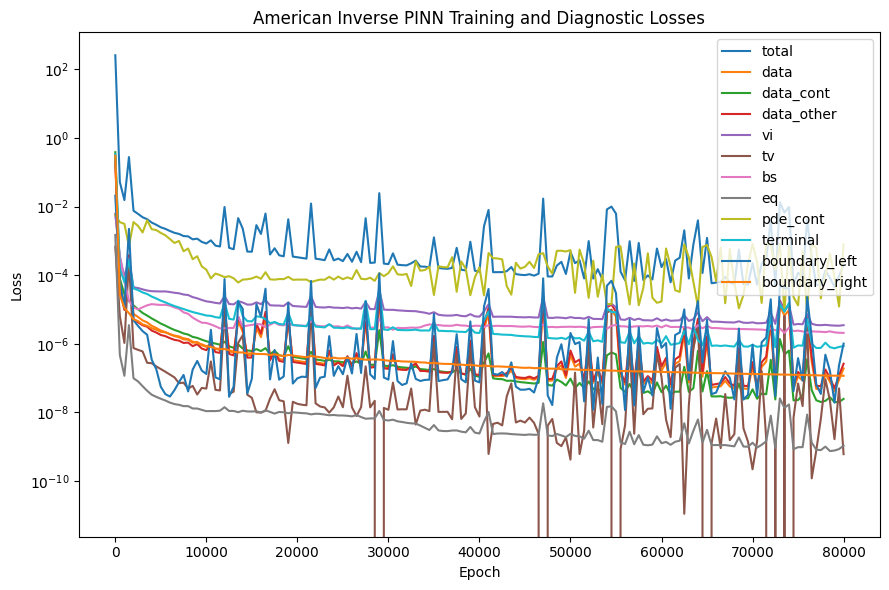

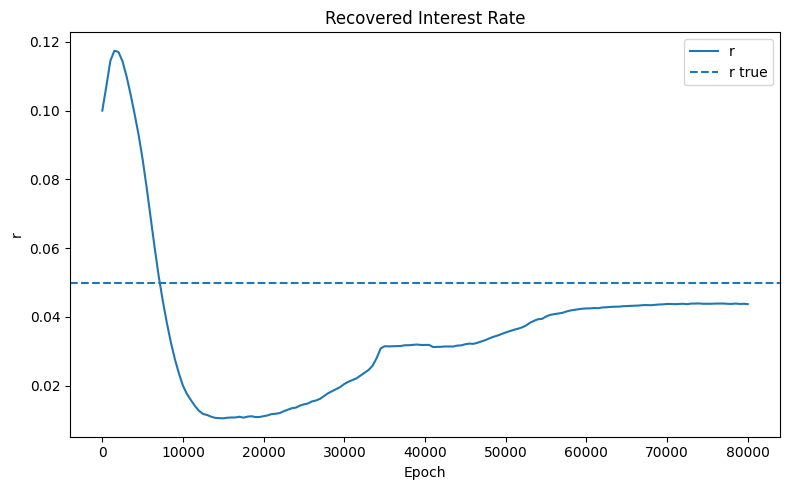

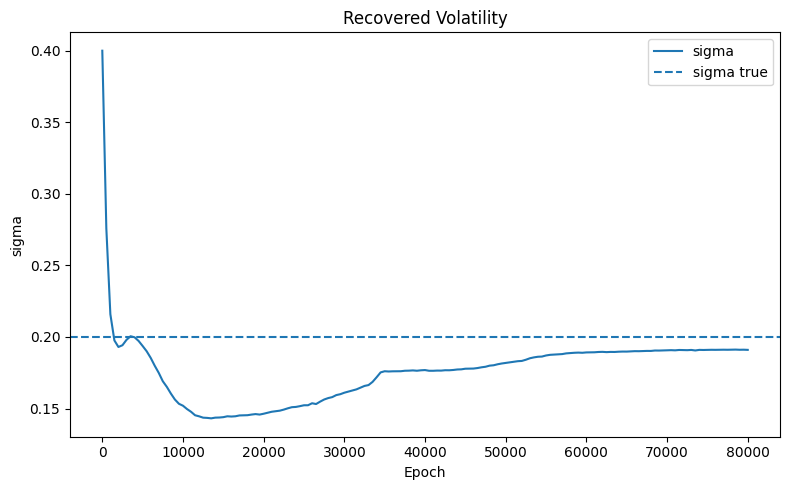

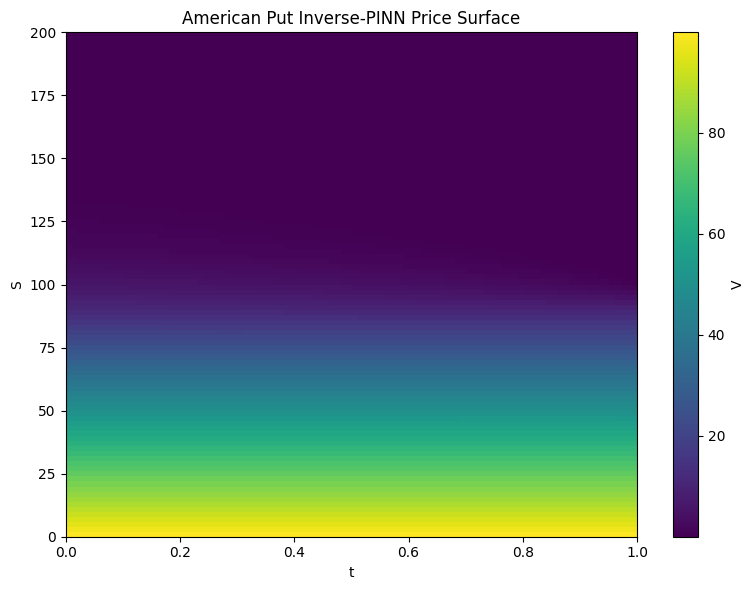

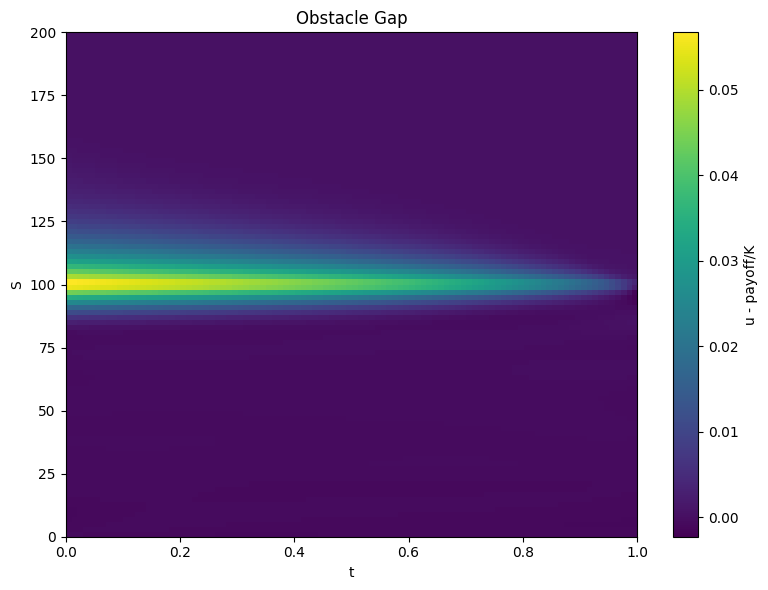

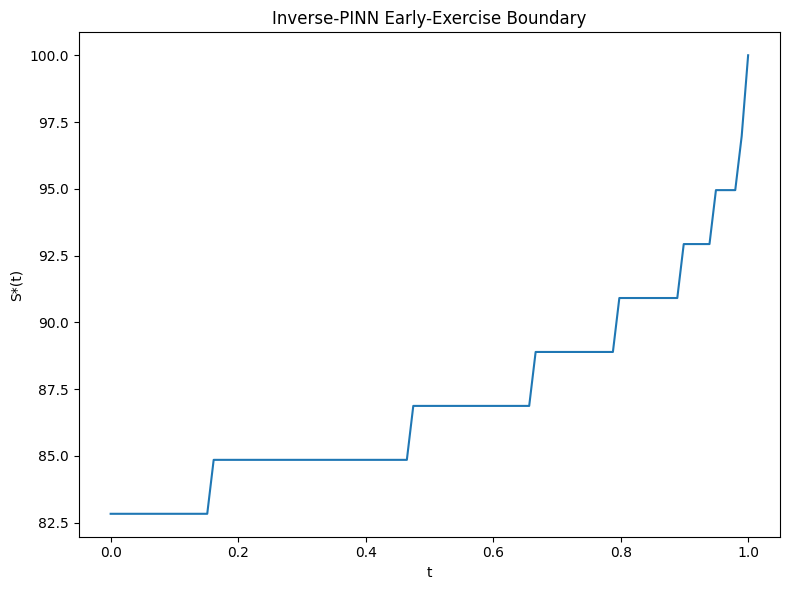

In [56]:
# Training losses
plt.figure(figsize=(9, 6))
for col in [
    "total", "data", "data_cont", "data_other",
    "vi", "tv", "bs", "eq", "pde_cont",
    "terminal", "boundary_left", "boundary_right"
]:
    if col in history_df.columns:
        plt.semilogy(
            history_df["epoch"],
            history_df[col],
            label=col
        )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("American Inverse PINN Training and Diagnostic Losses")
plt.legend()
plt.tight_layout()
plt.show()

# Recovered parameters
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["r"], label="r")
plt.axhline(r_true, linestyle="--", label="r true")
plt.xlabel("Epoch")
plt.ylabel("r")
plt.title("Recovered Interest Rate")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["sigma"], label="sigma")
plt.axhline(sigma_true, linestyle="--", label="sigma true")
plt.xlabel("Epoch")
plt.ylabel("sigma")
plt.title("Recovered Volatility")
plt.legend()
plt.tight_layout()
plt.show()

# PINN price surface
plt.figure(figsize=(8, 6))
plt.imshow(
    V_grid.T,
    origin="lower",
    aspect="auto",
    extent=[0.0, T, S_min, S_max]
)
plt.colorbar(label="V")
plt.xlabel("t")
plt.ylabel("S")
plt.title("American Put Inverse-PINN Price Surface")
plt.tight_layout()
plt.show()

# Obstacle gap
plt.figure(figsize=(8, 6))
plt.imshow(
    gap_u.T,
    origin="lower",
    aspect="auto",
    extent=[0.0, T, S_min, S_max]
)
plt.colorbar(label="u - payoff/K")
plt.xlabel("t")
plt.ylabel("S")
plt.title("Obstacle Gap")
plt.tight_layout()
plt.show()

# PINN boundary
plt.figure(figsize=(8, 6))
plt.plot(t_eval_np, B_pinn)
plt.xlabel("t")
plt.ylabel("S*(t)")
plt.title("Inverse-PINN Early-Exercise Boundary")
plt.tight_layout()
plt.show()
